# 04 · The forecast, its range and its flag

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p03_ro_fouling/notebooks/04_forecast.ipynb)

The forecast is deliberately simple: a robust straight line through the last six weeks of the
current cycle, read where it reaches the review level. Three things travel with every date: a
**P10–P90 range**, an **extrapolation flag**, and plain **refusals** when the data cannot carry a
date.

Script version: `step4_forecast_dev.py`, `step5_forecast_test.py` · record: `VALIDATION.md`,
sections 9–10.

In [1]:
# Setup. In Google Colab this installs the package from GitHub (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz]"
import os, subprocess, sys
REF = "main"        # before the Project 3 pull request is merged, use "p03-ro-fouling"
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    f"chemai[viz] @ git+https://github.com/EngMtaleb/chemai.git@{REF}"], check=True)
    os.environ["CHEMAI_DATA_DIR"] = "/content/data"     # where the deposit is downloaded

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
COL = {"A": "#2a6fb0", "B": "#128c84", "C": "#a8782f"}

## 1. Five cycles, five answers

In [2]:
from chemai.config import ROConfig
from chemai.models.fouling_forecast import forecast_cycle

cfg = ROConfig()
rng = np.random.default_rng(0)
t = np.arange(0, 43, dtype=float)
cases = {
    "steady rise":   1.05 + 0.0016 * t + rng.normal(0, 0.004, t.size),
    "accelerating":  1.03 + 0.03 * (np.exp(0.03 * t) - 1) + rng.normal(0, 0.004, t.size),
    "flat, noisy":   1.08 + rng.normal(0, 0.006, t.size),
    "falling":       1.12 - 0.0012 * t + rng.normal(0, 0.003, t.size),
    "already above": 1.14 + 0.001 * t + rng.normal(0, 0.003, t.size),
}
rows = []
for name, x in cases.items():
    f = forecast_cycle(t, x, review_level=1.15, cfg=cfg)
    rows.append(dict(cycle=name, status=f.status, now=f.level_now, per_week=f.rate_per_week,
                     P10=f.days_lo, P50=f.days_to_level, P90=f.days_hi, ratio=f.extrapolation_ratio,
                     flag="" if f.in_envelope else "FLAGGED"))
short = forecast_cycle(t[:8], cases["steady rise"][:8], 1.15)
rows.append(dict(cycle="one week of data", status=short.status))
pd.DataFrame(rows)

,cycle,status,now,per_week,P10,P50,P90,ratio,flag
0,steady rise,crossing,1.1185,0.01175,16.0,18.8,22.1,0.48,
1,accelerating,crossing,1.0984,0.01253,22.0,28.8,38.8,0.74,
2,"flat, noisy",not_in_sight,1.0799,-0.00026,NaN,NaN,NaN,NaN,
3,falling,falling,1.0691,-0.00871,NaN,NaN,NaN,NaN,
4,already above,at_or_above,1.1821,0.00722,0.0,0.0,0.0,NaN,
5,one week of data,insufficient,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print(short.warnings[0])

insufficient data: 5 points over 4 days since the cleaning (need 10 over 14)


### A straight line is late on acceleration

The accelerating cycle follows 1.03 + 0.03 (e^(0.03 t) − 1). Without the noise, when does it really
reach 1.15 — and how does that compare with the line's P10, P50 and P90?

In [4]:
t_true = np.log(1 + (1.15 - 1.03) / 0.03) / 0.03        # day the noiseless curve reaches 1.15
f = forecast_cycle(t, cases["accelerating"], 1.15, cfg=cfg)
print(f"truth: {t_true - 42:.1f} days after the last reading")
print(f"line : P10 {f.days_lo}, P50 {f.days_to_level}, P90 {f.days_hi} days")

truth: 11.6 days after the last reading
line : P10 22.0, P50 28.8, P90 38.8 days


Even the P10 is too late here. This is the limit measured on simulated biofilm plants, where the
P50 came a median 23 days after the true crossing: for a train that has fouled faster than
linearly before, plan by the P10 — and expect strong acceleration to beat even that.

## 2. Where the P10–P90 range comes from

A day-by-day record is autocorrelated, so a cycle is shorter in information than it looks. The
forecast draws plausible lines around the fit: the scatter of the residuals sets their spread, the
lag-1 autocorrelation shrinks the effective number of days, and one inflation factor (2.0) was
calibrated on simulated development plants to cover 80 % of true crossings. A residual bootstrap
was tried first and rejected: on a known line with autocorrelated noise it recovered only 41–84 % of
the slope's true spread (`step4b_interval_check.py` keeps that check on record).

residual scatter 0.0032, lag-1 autocorrelation 0.10


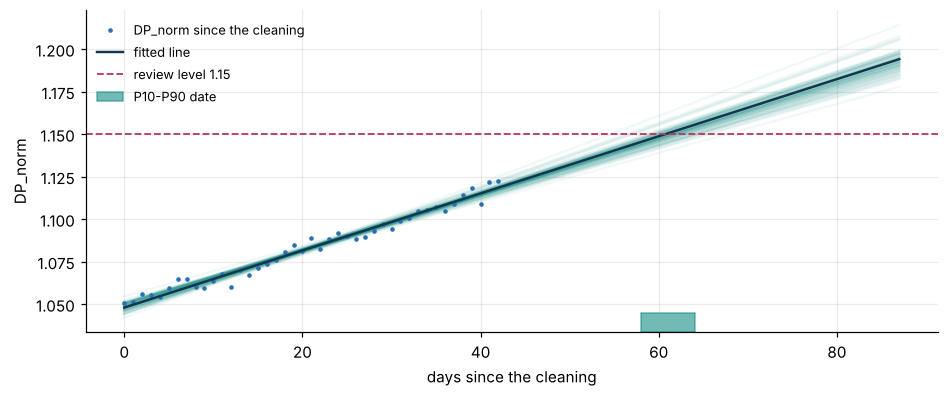

P50 in 18.8 days, P10 16.0, P90 22.1


In [5]:
from chemai.models.fouling_forecast import _fit_line, line_draws, prepare_window, residual_structure

x = cases["steady rise"]
tw, xw, _ = prepare_window(t, x, cfg)
a, b = _fit_line(tw, xw)                      # the same robust (Theil-Sen) line the forecast uses
sigma, rho = residual_structure(tw, xw, a, b)
ak, bk = line_draws(tw, xw, a, b, 200, cfg.interval_inflation, np.random.default_rng(1))
f = forecast_cycle(t, x, 1.15, cfg=cfg)
print(f"residual scatter {sigma:.4f}, lag-1 autocorrelation {rho:.2f}")

fig, ax = plt.subplots(figsize=(10, 3.8))
tt = np.linspace(0, 42 + 45, 200)
for ai, bi in zip(ak[:80], bk[:80]):
    ax.plot(tt, ai + bi * tt, color="#128c84", alpha=0.06)
ax.plot(t, x, ".", color="#2a6fb0", ms=4, label="DP_norm since the cleaning")
ax.plot(tt, a + b * tt, color="#14364c", lw=1.6, label="fitted line")
ax.axhline(1.15, color="#b53c58", ls="--", lw=1.2, label="review level 1.15")
ax.axvspan(42 + f.days_lo, 42 + f.days_hi, ymax=0.06, color="#128c84", alpha=0.6, label="P10-P90 date")
ax.set_xlabel("days since the cleaning"); ax.set_ylabel("DP_norm"); ax.legend(frameon=False, fontsize=8.5)
plt.show()
print(f"P50 in {f.days_to_level} days, P10 {f.days_lo}, P90 {f.days_hi}")

## 3. Scoring it where the truth is known

Six development plants (the first six of the thirty used to choose every setting), weekly
decisions from day 14 of each cycle, review levels 1.15 and 1.20, each forecast scored against the
counterfactual crossing. Three normalisations of the **same** plants. (A smaller run than the
script; the full numbers are in VALIDATION.md.)

In [6]:
from chemai.data.ro_sim import generate_plants
from chemai.evaluation.fouling_eval import score_sim, summarise

dev = generate_plants(6, seed=1001)
cache, scores = {}, {}
for name, fe, ve in (("own fit", "fit", None), ("vendor 1.5", 1.5, 0.25), ("linear 1.0", 1.0, 0.0)):
    scores[name] = score_sim(dev, (1.15, 1.20), "linear", cfg, flow_exponent=fe, visc_exponent=ve, cache=cache)
pd.DataFrame({k: summarise(v) for k, v in scores.items()}).loc[
    ["forecasts", "truth_inside_horizon", "dated", "median_abs_err_days", "bias_days", "coverage",
     "median_err_inside", "median_err_flagged"]]

,own fit,vendor 1.5,linear 1.0
forecasts,2369.000,2151.000,1466.000
truth_inside_horizon,1463.000,1406.000,996.000
dated,902.000,651.000,241.000
median_abs_err_days,17.800,29.600,31.000
bias_days,6.400,-1.000,8.400
coverage,0.825,0.883,0.925
median_err_inside,10.800,23.200,20.800
median_err_flagged,46.800,49.000,45.800


Same plants, same forecast — only the normalisation changed. The plant's own exponent dates far
more crossings, with a smaller error.

## 4. The extrapolation flag, measured

Error grows with how far ahead the line is asked to look, in multiples of the window it has seen.
Beyond 2×, the date is flagged.

In [7]:
sc = scores["own fit"]
g = sc[(sc["status"] == "crossing") & (sc["truth"] > 0) & (sc["truth"] <= 180)].copy()
g["error"] = (g["p50"] - g["truth"]).abs()
g["days ahead / days seen"] = pd.cut(g["ratio"], [0, 0.5, 1, 1.5, 2, 3, 5, 1e9])
g.groupby("days ahead / days seen", observed=True)["error"].agg(["count", "median"]).round(1)

,count,median
days ahead / days seen,,
"(0.0, 0.5]",152,5.1
"(0.5, 1.0]",173,11.5
"(1.0, 1.5]",128,17.2
"(1.5, 2.0]",121,23.8
"(2.0, 3.0]",154,37.8
"(3.0, 5.0]",136,58.9
"(5.0, 1000000000.0]",36,80.2


## 5. The decision: will it cross within 28 days?

The rival is the simplest rule a planner could use: *plan a cleaning when the last 7 days sit
within a margin of the level*. Same decisions, same truth.

In [8]:
def pr(sc, flag):
    g = sc[(sc["truth"] > 0) & (sc["status"] != "insufficient")]
    y = (g["truth"] <= 28).to_numpy()
    f = flag(g).to_numpy()
    tp, fp, fn = (f & y).sum(), (f & ~y).sum(), (~f & y).sum()
    return round(tp / max(tp + fn, 1), 2), round(tp / max(tp + fp, 1), 2)

rules = {
    "forecast: P50 within 28 days": lambda g: (g["status"] == "crossing") & (g["p50"].fillna(np.inf) <= 28),
    "margin 0.03": lambda g: g["obs_level_now"] >= g["level"] - 0.03,
    "margin 0.05": lambda g: g["obs_level_now"] >= g["level"] - 0.05,
    "both (the plan): forecast or margin 0.03": lambda g: ((g["status"] == "crossing") & (g["p50"].fillna(np.inf) <= 28))
                                                       | (g["obs_level_now"] >= g["level"] - 0.03),
}
pd.DataFrame({norm: {r: pr(scores[norm], f) for r, f in rules.items()} for norm in ("own fit", "vendor 1.5")}
             ).rename_axis("(recall, precision)")

,own fit,vendor 1.5
"(recall, precision)",,
forecast: P50 within 28 days,"(0.54, 0.78)","(0.31, 0.41)"
margin 0.03,"(0.27, 0.82)","(0.37, 0.51)"
margin 0.05,"(0.48, 0.73)","(0.5, 0.45)"
both (the plan): forecast or margin 0.03,"(0.6, 0.76)","(0.54, 0.44)"


With the plant's own exponent, the forecast holds its own against the margin rule in simulation;
with the vendor's, it loses. Combining both raises recall at nearly the same precision — the rule
the weekly plan uses (added after the real test; see notebook 05).

## What this notebook settled

- Every date comes with a **P10–P90 range**, a **flag**, or a **refusal**.
- **Normalisation** moved the result more than any model choice.
- The **flag works**: errors multiply beyond twice the window seen.
- On simulated plants the forecast is competitive with a simple margin rule — **if** the plant's own
  exponent is used.

Next: [05 · The real test and the weekly plan](05_real_test_and_plan.ipynb).